# Microplastic detection in water

A reproducible YOLOv8 experiment on real microscopy images, with dataset inspection, training, evaluation and calibrated inference.

**Dataset:** [andreusv / Microplastic-Fragments-WWTP-Dataset](https://huggingface.co/datasets/andreusv/Microplastic-Fragments-WWTP-Dataset), CC BY 4.0. The images contain wastewater-treatment-plant fragments; the model supports the annotated fragment class only. Images do not chemically confirm plastics.

**Experiment:** pretrained YOLOv8n, supplied train/validation/test splits, seed 42. Evaluate precision, recall, mAP50 and mAP50-95 on held-out data. Do not interpret confidence as accuracy.

## 1. Install and locate the project
For Colab, uncomment the installation cell. Upload and extract the project ZIP to `/content` first, or use the dataset preparation cells below. Local users can run this in `new_env`.

In [1]:
# %pip install ultralytics pyarrow requests pyyaml pandas matplotlib pillow nbformat


In [2]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml, torch
from PIL import Image
from ultralytics import YOLO

# Local: launch Jupyter from this project. Colab: upload/extract the shared ZIP,
# or set PROJECT_ROOT to its extracted directory.
candidates = [Path(os.environ.get("PROJECT_ROOT", ".")), Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p / "backend" / "main.py").exists()), None)
if ROOT is None:
    ROOT = Path("/content/Microplastic_Detection_Sachin")
    ROOT.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "ml/data"
MODELS = ROOT / "ml/models"
OUTPUT = ROOT / "ml/notebook_outputs"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Project:", ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


C:\Users\suhas\anaconda3\envs\new_env\lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Project: C:\Users\suhas\OneDrive\Desktop\Microplastic_Detection_Sachin
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Reproducible data preparation
The code below is included in this notebook and exports the same script used for the delivered dataset. It preserves the publisher splits, maps foreground class 1 to YOLO class 0, validates boxes, checks exact duplicate images across splits and creates `data.yaml`. Images are proportionally resized to at most 1280 pixels for a portable dataset.

Set `DOWNLOAD_DATA=True` to fetch approximately 1.3 GB of original Parquet data. Leave it false when using the supplied processed dataset.

In [3]:
DOWNLOAD_DATA = False
prepare_source = '"""Download the attributed CC BY 4.0 dataset and convert COCO boxes to YOLO."""\nfrom pathlib import Path\nimport io, json, hashlib, time\nimport requests, yaml\nimport pyarrow.parquet as pq\nfrom PIL import Image\n\nROOT = Path(__file__).resolve().parents[2]\nREPO = \'andreusv/Microplastic-Fragments-WWTP-Dataset\'\nREVISION = \'bdbb9dd898b7d96187e1d7e4f1a49babc85f3160\'\nDATA = ROOT / \'ml/data\'\n\ndef prepare():\n    raw = DATA / \'raw\'; raw.mkdir(parents=True, exist_ok=True)\n    card = requests.get(f\'https://huggingface.co/datasets/{REPO}/raw/{REVISION}/README.md\', timeout=60)\n    card.raise_for_status(); (DATA / \'SOURCE_DATASET_CARD.md\').write_text(card.text, encoding=\'utf-8\')\n    listing = requests.get(f\'https://huggingface.co/api/datasets/{REPO}/tree/{REVISION}/data\', timeout=60)\n    listing.raise_for_status(); meta = listing.json()\n    stats = {}; hashes = {}; duplicates = []\n    for item in meta:\n        name = item[\'path\']; target = raw / Path(name).name\n        if not target.exists() or target.stat().st_size != item[\'size\']:\n            print(\'Downloading\', name, flush=True)\n            for attempt in range(4):\n                try:\n                    with requests.get(f\'https://huggingface.co/datasets/{REPO}/resolve/{REVISION}/{name}?download=true\', stream=True, timeout=120) as response:\n                        response.raise_for_status()\n                        with target.with_suffix(\'.part\').open(\'wb\') as out:\n                            for chunk in response.iter_content(1024*1024): out.write(chunk)\n                    target.with_suffix(\'.part\').replace(target); break\n                except requests.RequestException:\n                    if attempt == 3: raise\n                    time.sleep(2)\n        source_split = Path(name).name.split(\'-\')[0]\n        split = \'val\' if source_split == \'validation\' else source_split\n        image_dir = DATA / split / \'images\'; label_dir = DATA / split / \'labels\'\n        image_dir.mkdir(parents=True, exist_ok=True); label_dir.mkdir(parents=True, exist_ok=True)\n        stat = stats.setdefault(split, {\'images\':0,\'boxes\':0,\'background_images\':0})\n        for batch in pq.ParquetFile(target).iter_batches(batch_size=32):\n            for row in batch.to_pylist():\n                blob = row[\'image\'][\'bytes\']; digest = hashlib.sha256(blob).hexdigest()\n                if digest in hashes:\n                    duplicates.append({\'sha256\':digest,\'first\':hashes[digest],\'second\':split})\n                    continue\n                hashes[digest] = split\n                image = Image.open(io.BytesIO(blob)).convert(\'RGB\'); w,h = image.size\n                objects = row[\'objects\']; labels = []\n                for box, category in zip(objects[\'bbox\'], objects[\'category_id\']):\n                    if category != 1: raise ValueError(f\'Unexpected class {category}\')\n                    x,y,bw,bh = map(float,box)\n                    x1,y1 = max(0,x),max(0,y); x2,y2 = min(w,x+bw),min(h,y+bh)\n                    if x2<=x1 or y2<=y1: raise ValueError(\'Invalid box\')\n                    labels.append(f\'0 {(x1+x2)/2/w:.8f} {(y1+y2)/2/h:.8f} {(x2-x1)/w:.8f} {(y2-y1)/h:.8f}\')\n                stem = f\'{split}_{stat["images"]:05d}\'\n                # Resize proportionally for portable distribution; normalized annotations remain valid.\n                image.thumbnail((1280,1280)); image.save(image_dir / (stem+\'.jpg\'), quality=92)\n                (label_dir / (stem+\'.txt\')).write_text(\'\\n\'.join(labels), encoding=\'utf-8\')\n                stat[\'images\']+=1; stat[\'boxes\']+=len(labels); stat[\'background_images\']+=not labels\n        print(split, stat, flush=True)\n    config = {\'path\':str(DATA.resolve()),\'train\':\'train/images\',\'val\':\'val/images\',\'test\':\'test/images\',\'names\':{0:\'microplastic_fragment\'},\'nc\':1}\n    (DATA/\'data.yaml\').write_text(yaml.safe_dump(config),encoding=\'utf-8\')\n    summary = {\'source\':f\'https://huggingface.co/datasets/{REPO}\',\'revision\':REVISION,\'license\':\'CC BY 4.0\',\'stats\':stats,\'duplicates_removed\':duplicates,\'images_sha256\':hashes,\'conversion\':\'COCO xywh to normalized YOLO xywh; resized longest side <=1280\'}\n    (DATA/\'dataset_audit.json\').write_text(json.dumps(summary,indent=2),encoding=\'utf-8\')\n    return stats\n\nif __name__ == \'__main__\': prepare()\n'
script_path=ROOT/"ml/scripts/prepare_data.py"
script_path.parent.mkdir(parents=True, exist_ok=True)
script_path.write_text(prepare_source, encoding="utf-8")
if DOWNLOAD_DATA:
    namespace={"__file__":str(script_path),"__name__":"dataset_tools"}
    exec(compile(prepare_source,str(script_path),"exec"),namespace)
    namespace["prepare"]()


## 3. Inspect splits, classes and annotations

Classes: {0: 'microplastic_fragment'}


,images,boxes,background_images
test,302,852,1
train,1406,2915,5
val,302,790,0


Exact duplicate images removed: 0


,split,images,valid_annotations
0,train,1406,2915
1,val,302,790
2,test,302,852


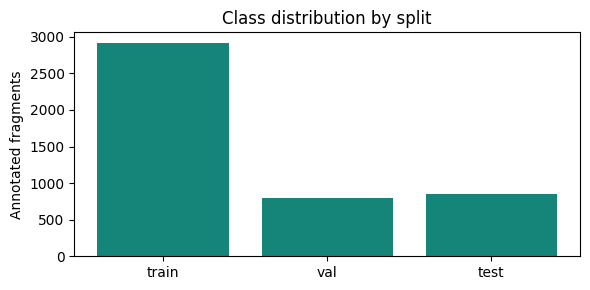

In [4]:
config = yaml.safe_load((DATA / "data.yaml").read_text())
config["path"] = str(DATA.resolve())
(DATA / "data.yaml").write_text(yaml.safe_dump(config))
names = config["names"]
print("Classes:", names)
audit = json.loads((DATA / "dataset_audit.json").read_text())
display(pd.DataFrame(audit["stats"]).T)
print("Exact duplicate images removed:", len(audit["duplicates_removed"]))
checks = []; class_counts = {}
for split in ["train", "val", "test"]:
    images = sorted((DATA / split / "images").glob("*.jpg"))
    total = 0
    for path in images:
        label_path = DATA / split / "labels" / (path.stem + ".txt")
        assert label_path.exists(), f"Missing label: {path.name}"
        for line in label_path.read_text().splitlines():
            values = list(map(float, line.split()))
            assert len(values) == 5 and values[0] in names
            assert all(np.isfinite(values)) and all(0 <= v <= 1 for v in values[1:])
            assert values[3] > 0 and values[4] > 0
            total += 1
    class_counts[split] = total
    checks.append({"split": split, "images": len(images), "valid_annotations": total})
display(pd.DataFrame(checks))
plt.figure(figsize=(6,3)); plt.bar(class_counts.keys(), class_counts.values(), color="#168579")
plt.ylabel("Annotated fragments"); plt.title("Class distribution by split"); plt.tight_layout(); plt.show()


## 4. Inspect ground-truth bounding boxes

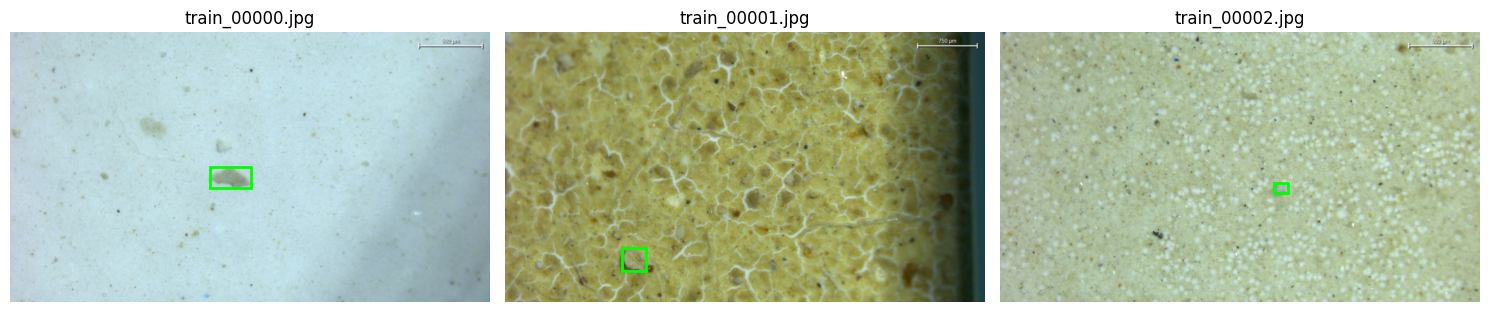

In [5]:
from matplotlib.patches import Rectangle
sample_paths = sorted((DATA / "train/images").glob("*.jpg"))[:3]
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, path in zip(axes, sample_paths):
    image = Image.open(path); w, h = image.size; ax.imshow(image)
    for line in (DATA / "train/labels" / (path.stem + ".txt")).read_text().splitlines():
        cls, cx, cy, bw, bh = map(float, line.split())
        ax.add_patch(Rectangle(((cx-bw/2)*w,(cy-bh/2)*h),bw*w,bh*h,fill=False,color="lime",linewidth=2))
    ax.set_title(path.name); ax.axis("off")
plt.tight_layout(); plt.savefig(OUTPUT / "ground_truth_samples.png", dpi=130); plt.show()


## 5. Train YOLOv8
Set `RUN_TRAINING=True` to reproduce training. The default uses the trained `best.pt` already supplied, so Run All does not overwrite it. The seed improves reproducibility; hardware/library differences can still change results.

Training selects weights using validation performance. The test split is never used for training or checkpoint selection.

In [6]:
RUN_TRAINING = False
EPOCHS = 40
IMAGE_SIZE = 640
BATCH_SIZE = 12
training_source = "from pathlib import Path\nimport argparse, json, shutil, math\nimport torch, yaml\nfrom ultralytics import YOLO\n\nROOT = Path(__file__).resolve().parents[2]\n\ndef train(epochs=40, imgsz=640, batch=12):\n    data = ROOT/'ml/data/data.yaml'\n    config = yaml.safe_load(data.read_text()); config['path'] = str(data.parent.resolve())\n    data.write_text(yaml.safe_dump(config))\n    model = YOLO('yolov8n.pt')\n    model.train(data=str(data), epochs=epochs, imgsz=imgsz, batch=batch,\n                device=0 if torch.cuda.is_available() else 'cpu', workers=4,\n                project=str(ROOT/'ml/runs'), name='fragment_detector', exist_ok=True,\n                seed=42, deterministic=True, patience=12, plots=True, cache=False,\n                close_mosaic=8, amp=False)\n    target = ROOT/'ml/models'; target.mkdir(parents=True, exist_ok=True)\n    for name in ['best.pt','last.pt']:\n        source=ROOT/'ml/runs/fragment_detector/weights'/name\n        checkpoint = torch.load(source,weights_only=False,map_location='cpu')\n        fitted = checkpoint.get('ema') or checkpoint.get('model')\n        if not all(torch.isfinite(v).all() for v in fitted.state_dict().values()):\n            raise RuntimeError('Non-finite model weights; do not use this model.')\n        shutil.copy2(source, target/name)\n    evaluate()\n\ndef evaluate():\n    data = ROOT/'ml/data/data.yaml'\n    config = yaml.safe_load(data.read_text()); config['path'] = str(data.parent.resolve())\n    data.write_text(yaml.safe_dump(config))\n    model = YOLO(str(ROOT/'ml/models/best.pt'))\n    output = {}\n    for split in ['val','test']:\n        metric = model.val(data=str(ROOT/'ml/data/data.yaml'),split=split,imgsz=640,batch=12,\n                           device=0 if torch.cuda.is_available() else 'cpu',workers=0,\n                           project=str(ROOT/'ml/evaluation'),name=split,exist_ok=True,plots=True)\n        output[split] = {k:float(v) for k,v in metric.results_dict.items()}\n        if not all(math.isfinite(v) for v in output[split].values()):\n            raise RuntimeError('Evaluation produced non-finite metrics.')\n        output[split]['speed_ms_per_image'] = metric.speed\n    (ROOT/'ml/evaluation/metrics.json').write_text(json.dumps(output,indent=2))\n    return output\n\nif __name__=='__main__':\n    parser=argparse.ArgumentParser(); parser.add_argument('--epochs',type=int,default=40)\n    parser.add_argument('--imgsz',type=int,default=640); parser.add_argument('--batch',type=int,default=12)\n    args=parser.parse_args(); train(args.epochs,args.imgsz,args.batch)\n"
training_path=ROOT/"ml/scripts/train.py"
training_path.parent.mkdir(parents=True, exist_ok=True)
training_path.write_text(training_source, encoding="utf-8")
training_namespace={"__file__":str(training_path),"__name__":"training_tools"}
exec(compile(training_source,str(training_path),"exec"),training_namespace)
if RUN_TRAINING:
    training_namespace["train"](EPOCHS,IMAGE_SIZE,BATCH_SIZE)
else:
    assert (MODELS/"best.pt").exists(), "Train first, or extract the supplied model from the project ZIP."
    print("Using the supplied trained model.")


Using the supplied trained model.


## 6. Evaluate and inspect actual metrics
`RUN_EVALUATION=True` recomputes validation and held-out test evaluation. Otherwise this reads the actual evaluation saved with the project.

,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),fitness
val,0.764548,0.777215,0.852741,0.677043,0.677043
test,0.799657,0.763619,0.853511,0.689310,0.689310


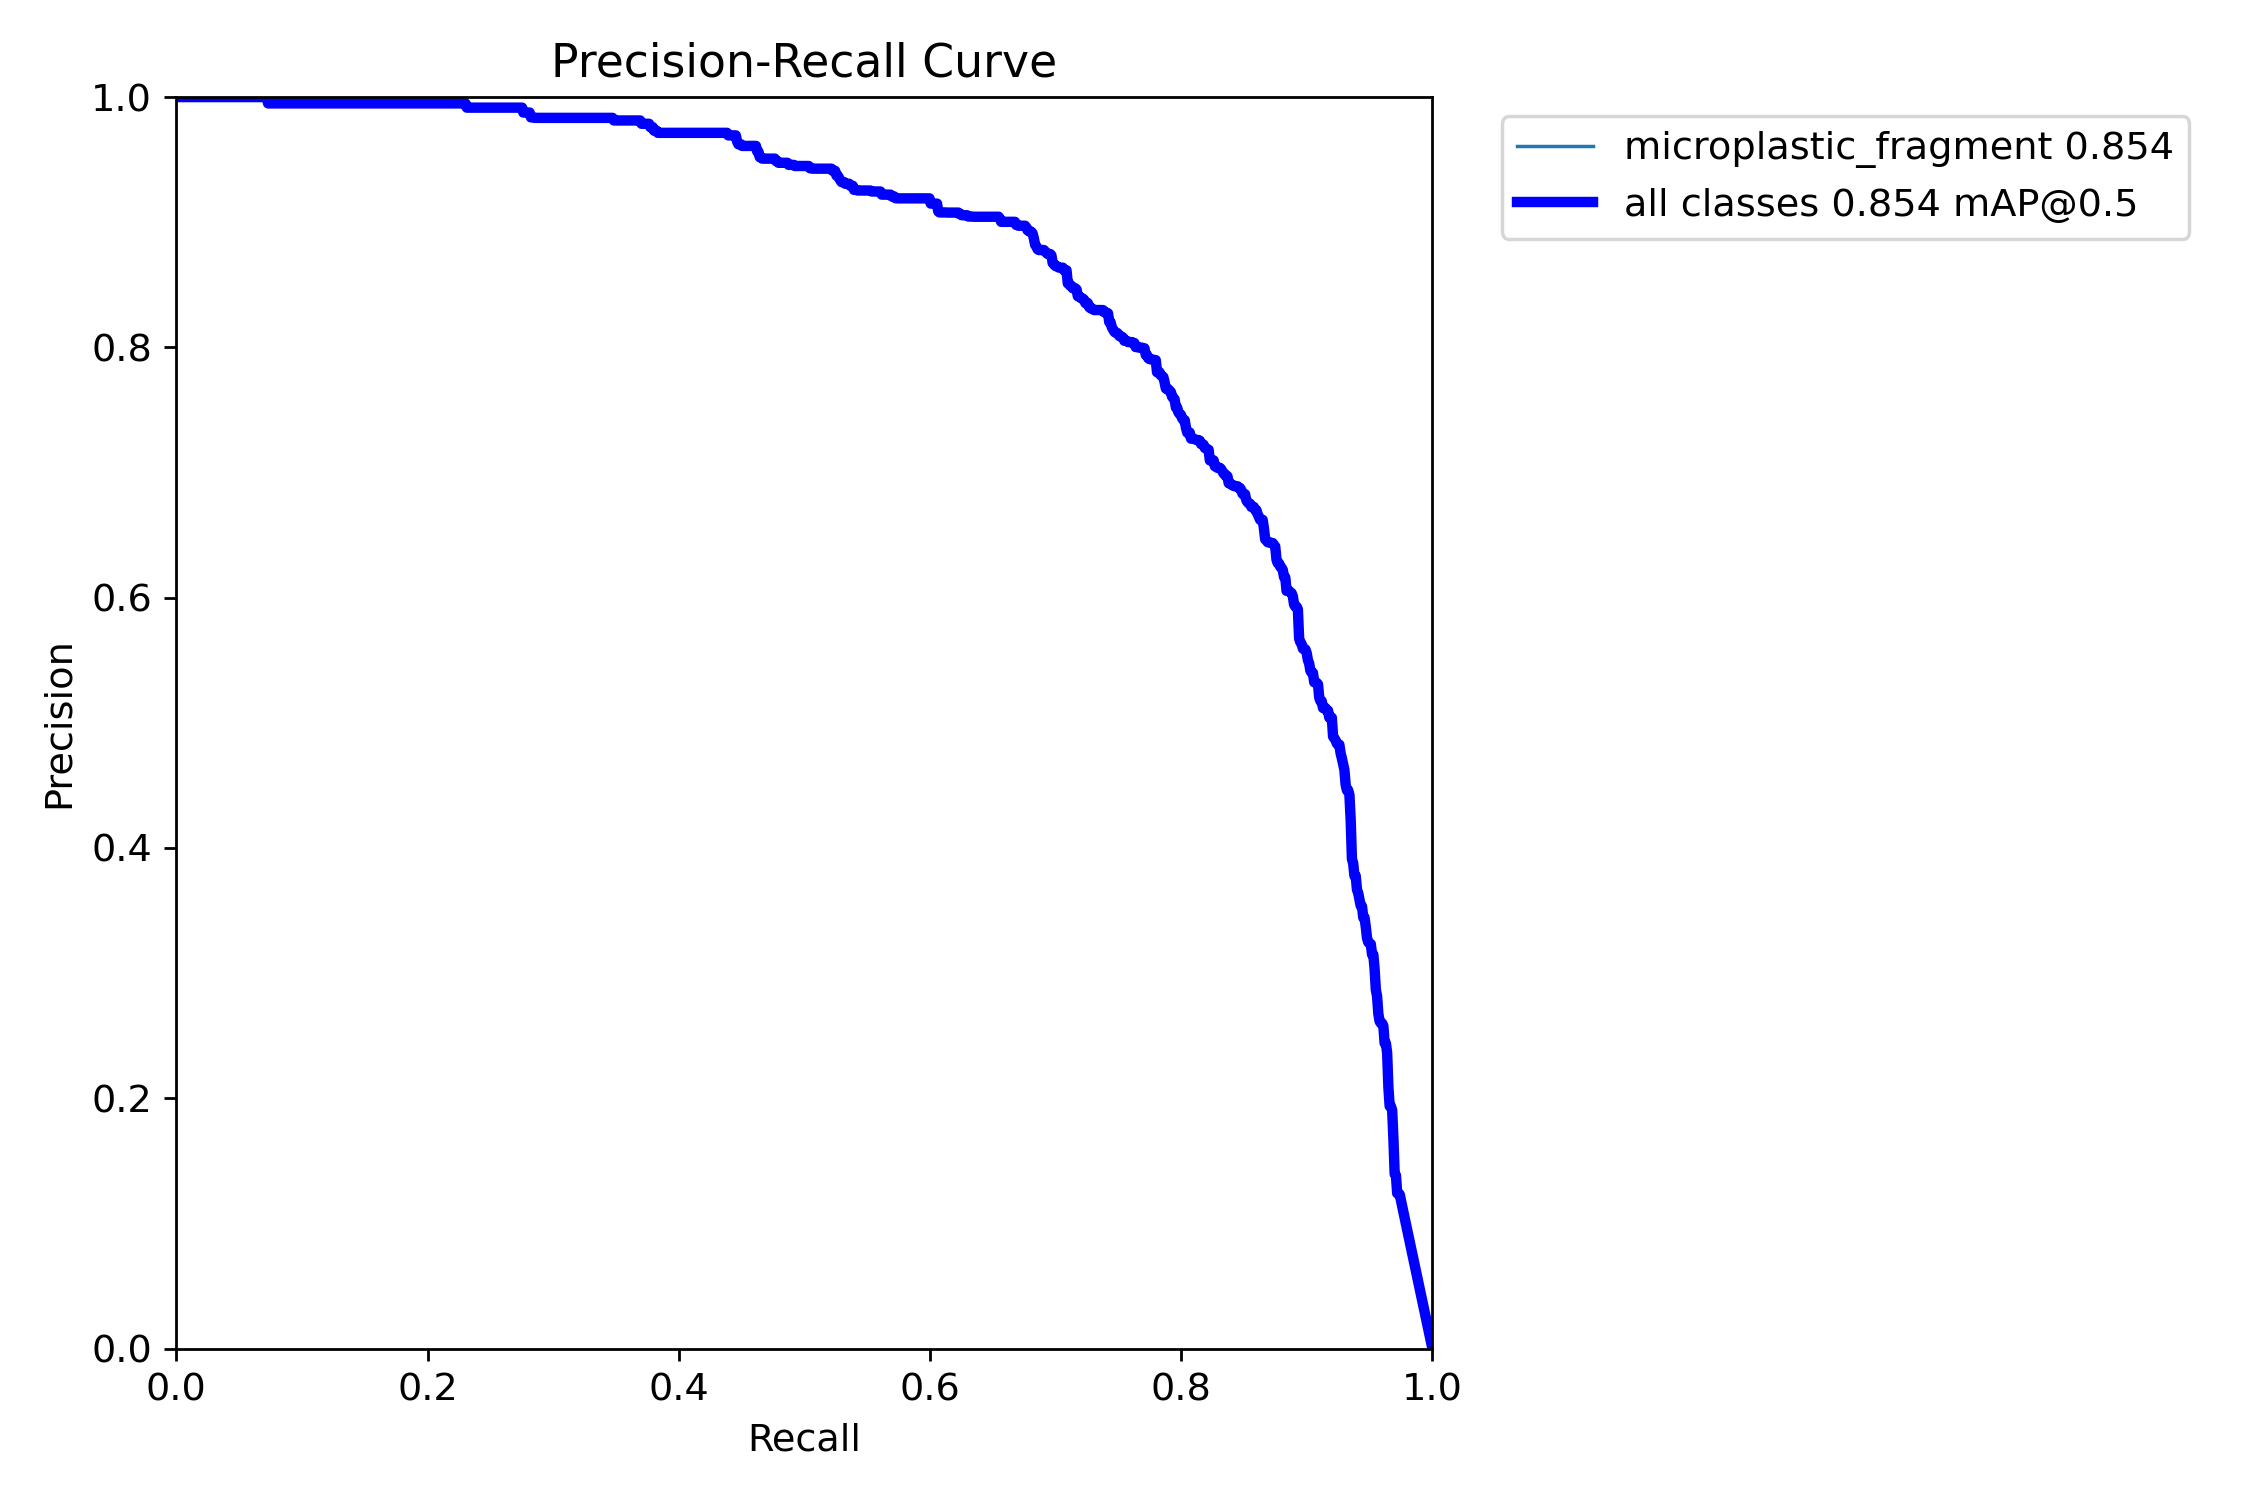

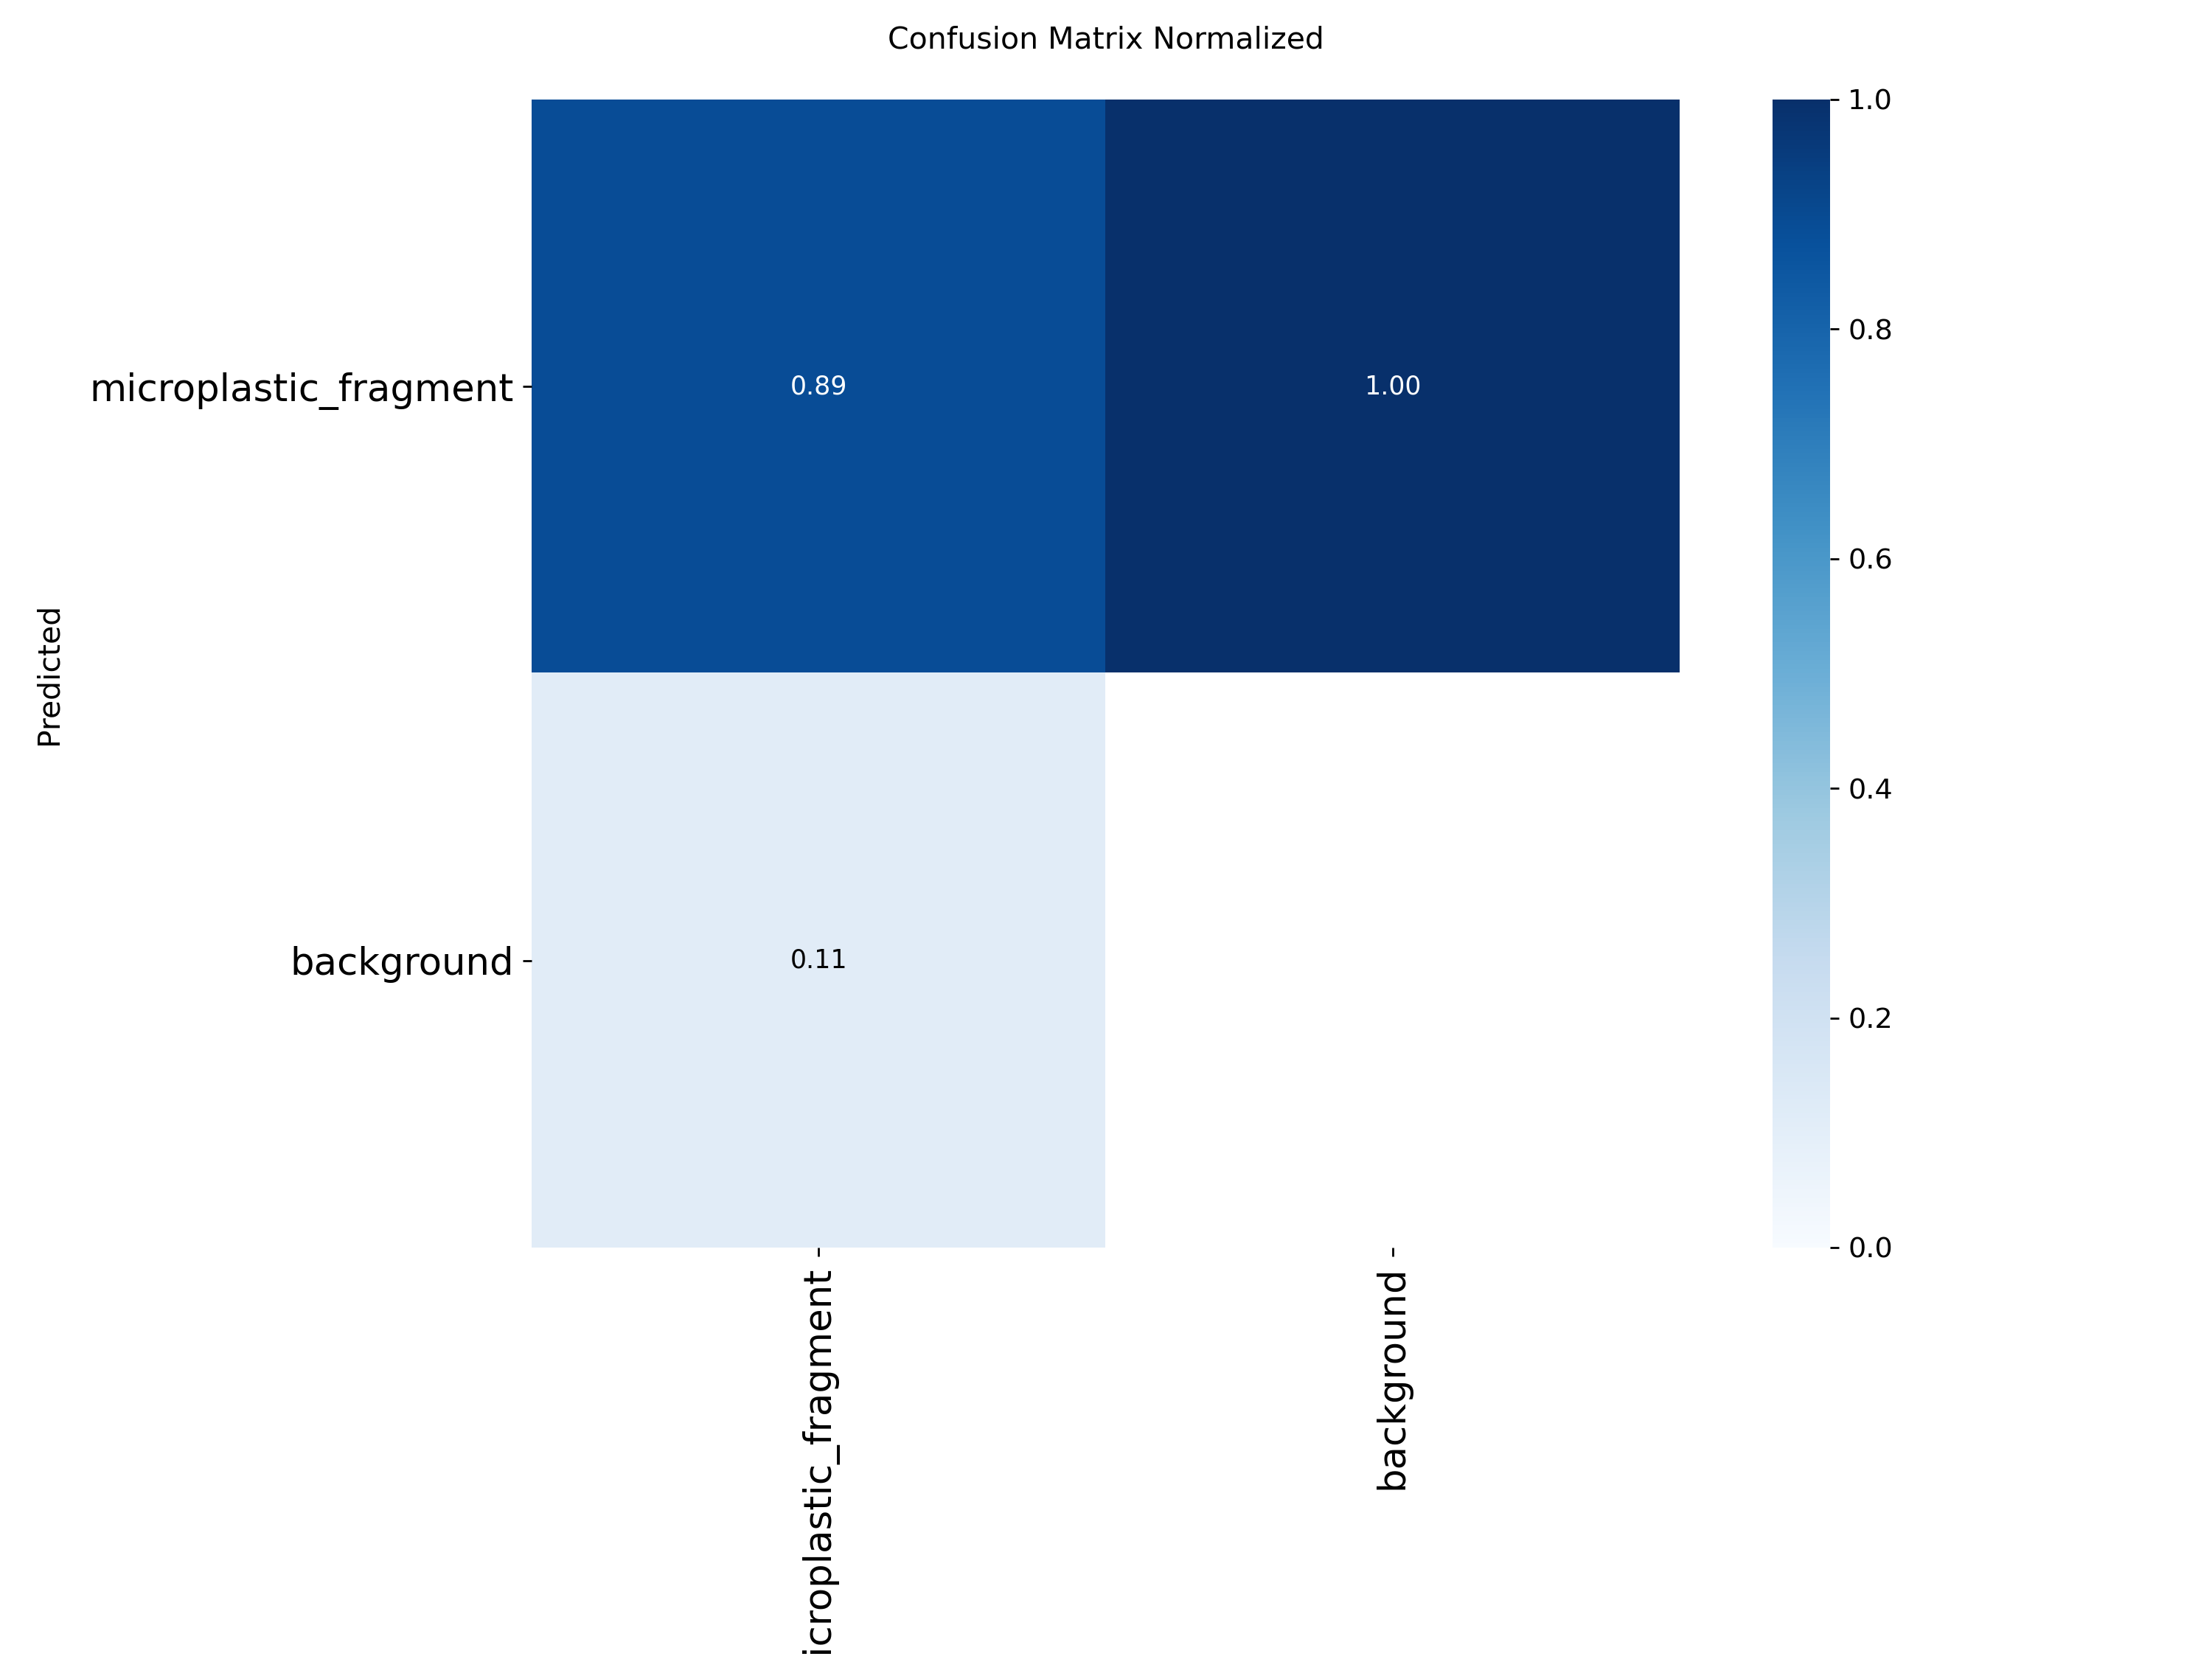

In [7]:
RUN_EVALUATION = False
if RUN_EVALUATION:
    training_namespace["evaluate"]()
metrics = json.loads((ROOT / "ml/evaluation/metrics.json").read_text())
display(pd.DataFrame({split:{k:v for k,v in m.items() if k != "speed_ms_per_image"} for split,m in metrics.items()}).T)
for name in ["BoxPR_curve.png", "confusion_matrix_normalized.png"]:
    path = ROOT / "ml/evaluation/test" / name
    if path.exists():
        display(Image.open(path))


## 7. Analyze a held-out test image
Set `IMAGE_PATH` to another microscopic JPEG/PNG to try it. `UM_PER_PIXEL` must come from a real calibration; leave it `None` to report pixels. Low/Moderate/High bands below are configurable count demonstrations, not concentration or safety measurements.

,particle_id,class_name,confidence,x1,y1,x2,y2,width_pixels,height_pixels,area_pixels
0,1,microplastic_fragment,0.825025,886.698303,295.770508,918.517151,326.908203,31.818848,31.137695,990.765584
1,2,microplastic_fragment,0.788773,485.465576,521.868408,553.821167,589.971191,68.355591,68.102783,4655.205982
2,3,microplastic_fragment,0.570012,329.343872,399.827087,381.417725,482.608337,52.073853,82.781250,4310.738605
3,4,microplastic_fragment,0.460235,992.558594,403.441956,1051.224854,445.126892,58.666260,41.684937,2445.499314


Suspected fragments: 4 | Project-defined image count band: Low
Inference timing (ms): {'preprocess': 1.2759000092046335, 'inference': 40.43130000354722, 'postprocess': 10.503100013011135}


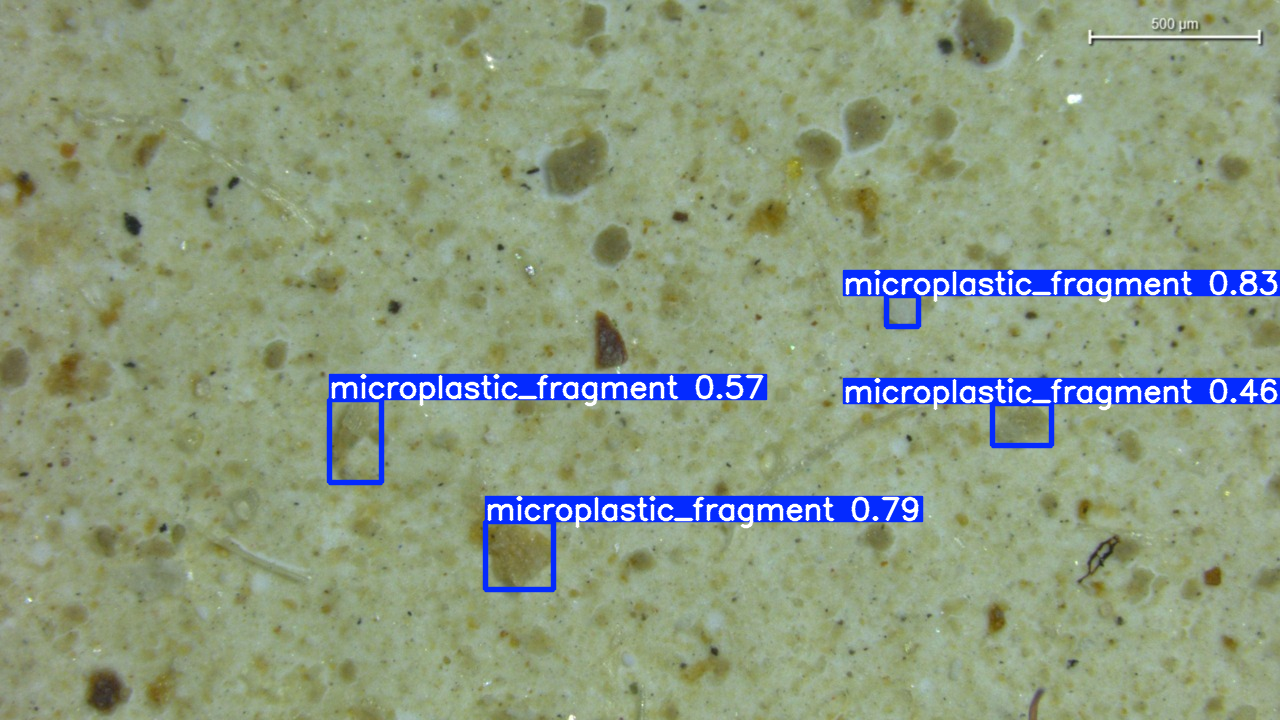

In [8]:
IMAGE_PATH = sorted((DATA / "test/images").glob("*.jpg"))[0]
CONFIDENCE = 0.25
UM_PER_PIXEL = None
model = YOLO(str(MODELS / "best.pt"))
prediction = model.predict(str(IMAGE_PATH), conf=CONFIDENCE, imgsz=640, verbose=False)[0]
rows = []
for i, box in enumerate(prediction.boxes):
    x1,y1,x2,y2 = map(float, box.xyxy[0].tolist())
    row = {"particle_id":i+1,"class_name":model.names[int(box.cls[0])],"confidence":float(box.conf[0]),
           "x1":x1,"y1":y1,"x2":x2,"y2":y2,"width_pixels":x2-x1,"height_pixels":y2-y1,"area_pixels":(x2-x1)*(y2-y1)}
    if UM_PER_PIXEL is not None:
        assert UM_PER_PIXEL > 0
        row.update(width_um=(x2-x1)*UM_PER_PIXEL,height_um=(y2-y1)*UM_PER_PIXEL)
    rows.append(row)
frame = pd.DataFrame(rows)
display(frame)
frame.to_csv(OUTPUT / "sample_detections.csv", index=False)
count = len(rows)
thresholds = json.loads((ROOT / "backend/config.json").read_text()) if (ROOT / "backend/config.json").exists() else {"moderate_count":10,"high_count":30}
band = "High" if count >= thresholds["high_count"] else "Moderate" if count >= thresholds["moderate_count"] else "Low"
print("Suspected fragments:",count,"| Project-defined image count band:",band)
print("Inference timing (ms):", prediction.speed)
annotated = Image.fromarray(prediction.plot()[..., ::-1])
annotated.save(OUTPUT / "sample_annotated.jpg")
display(annotated)


## Conclusions and limitations
Report the saved test precision/recall/mAP values, describe the fragment-only class, and show the annotated sample and detection table. This dataset covers prepared wastewater microscopy and does not establish generalization to arbitrary water-sample images. Annotation judgment and visually similar debris can cause errors. Chemical confirmation and laboratory sample metadata remain outside the image-only project.

The dashboard and PDF functionality are implemented in the accompanying `microplastic_python_implementation.ipynb`, which contains every runtime Python source file for review and export.